# Question 2 — The Parallax Trap: Can One Homography Align Everything?
**Computer Vision Lab · Assignment 4** · 

**Scene.** Two photos of the *Fulgar* hostel entrance, taken from slightly different positions (`fulgar_1.jpg`, `fulgar_2.jpg`, 1200×1600). The scene contains
* a **near object** – the entrance canopy with its string-lights, the plant pots and the shrubs (a few metres from the camera), and
* a **distant background** – the upper floors / tower of the building facade (much further away).

**Goal.** Estimate a homography from *background* features, warp image 2 into the frame of image 1, and measure how well the background and the near object are aligned. Then repeat using *near-object* features and compare. Finally explain the result and show how accuracy can be improved.

*Convention:* the homography maps image-2 points to image-1 points, `x₁ ≃ H x₂`, and image 2 is warped into image 1's coordinate system.

image size 1200 x 1600


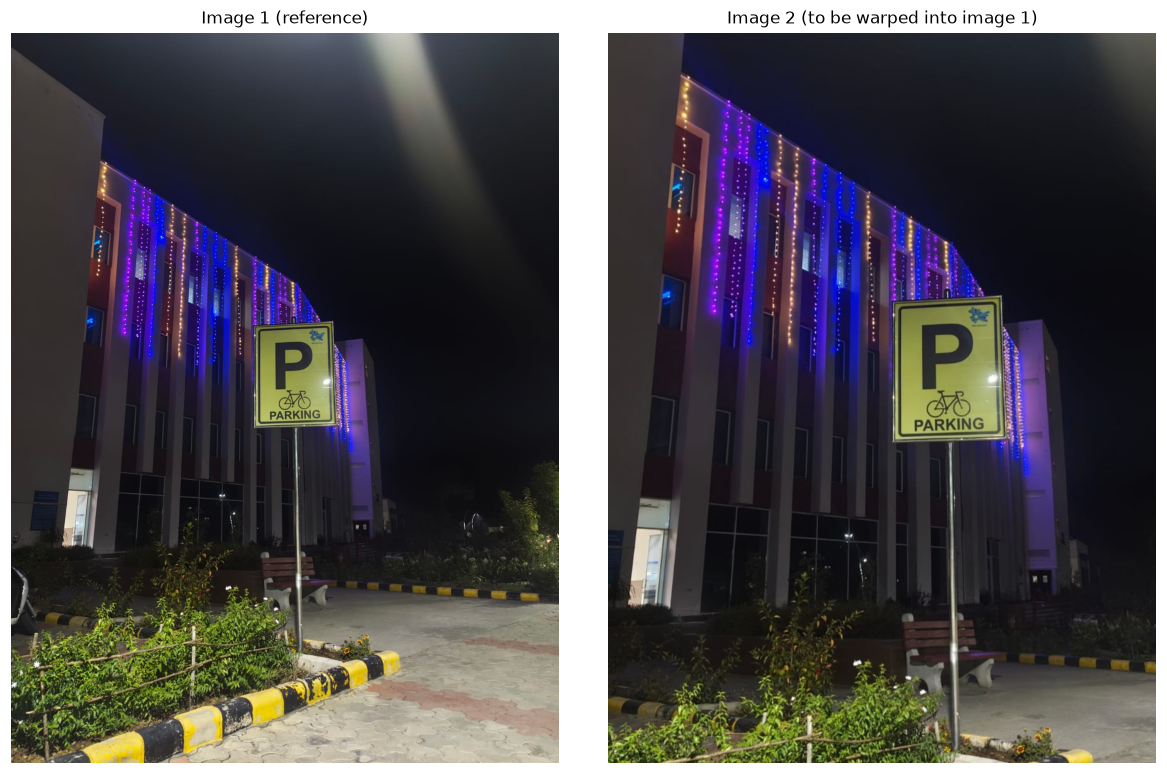

In [11]:
import cv2, numpy as np, matplotlib.pyplot as plt, pandas as pd
from pathlib import Path

np.random.seed(0)
OUT = Path("outputs")
OUT.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9})
I1 = cv2.cvtColor(cv2.imread("images/parking_scene.jpg"), cv2.COLOR_BGR2RGB)
I2 = cv2.cvtColor(cv2.imread("images/parking_scene_2.jpg"), cv2.COLOR_BGR2RGB)
h, w = I1.shape[:2]
print("image size", w, "x", h)
fig, axs = plt.subplots(1, 2, figsize=(11, 7))
axs[0].imshow(I1)
axs[1].imshow(I2)
axs[0].set_title("Image 1 (reference)")
axs[1].set_title("Image 2 (to be warped into image 1)")
for a in axs:
    a.axis("off")
plt.tight_layout()
plt.show()


## 1. Features, matches and the two regions (Task 1)
SIFT keypoints → ratio test (0.75) + mutual check → keep only matches that satisfy a *loose epipolar constraint* (F-RANSAC, 0.7 px) so mismatches are removed **without** assuming a particular depth plane (a homography-based filter would bias the experiment).

Regions are defined in image 1 (rectangles chosen by eye):
* **Background region** – upper facade/tower: `y < 880`
* **Near-object region** – entrance canopy, string-lights, plants and pots: `y > 1000`, `300 < x < 1150`

keypoints 7980/4413, mutual+ratio matches 2453, epipolar-consistent matches 2432
background features: 662 | near-object features: 1279 | others (not used for fitting): 491


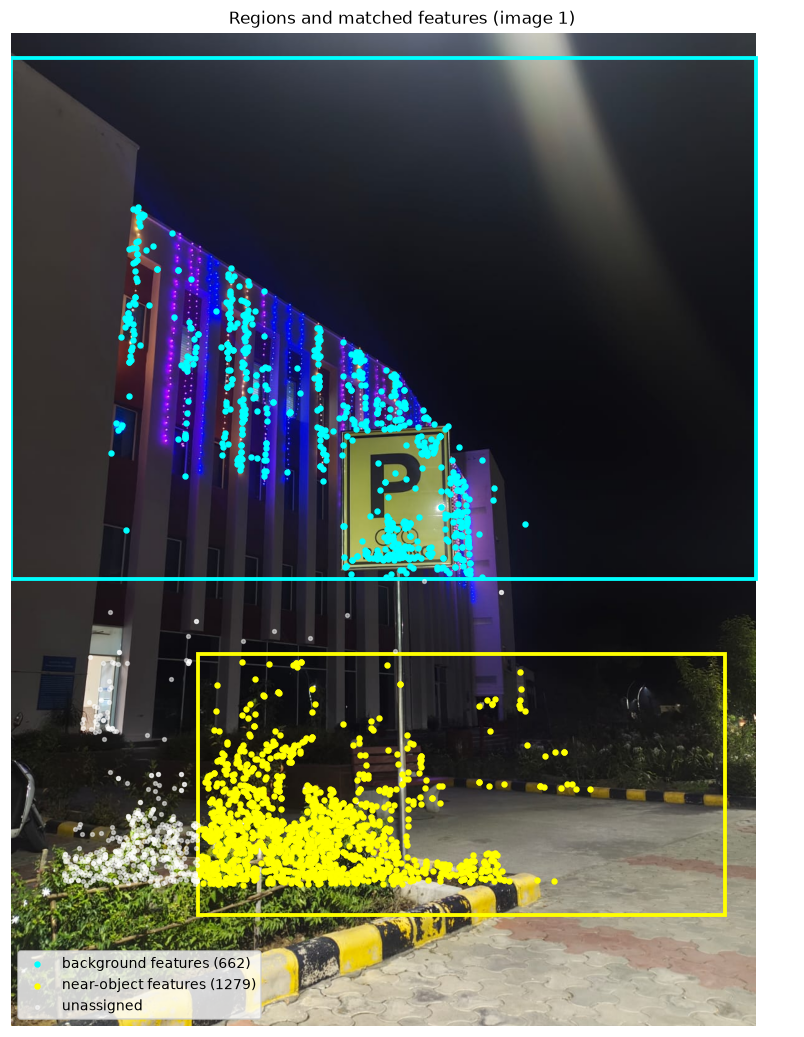

In [12]:
g1 = cv2.cvtColor(I1, cv2.COLOR_RGB2GRAY)
g2 = cv2.cvtColor(I2, cv2.COLOR_RGB2GRAY)
sift = cv2.SIFT_create(10000)
k1, d1 = sift.detectAndCompute(g1, None)
k2, d2 = sift.detectAndCompute(g2, None)
bf = cv2.BFMatcher()
fw = bf.knnMatch(d1, d2, k=2)
bw = {m.queryIdx: m.trainIdx for m in bf.match(d2, d1)}
good = [
    m
    for m, n in fw
    if m.distance < 0.75 * n.distance and bw.get(m.trainIdx) == m.queryIdx
]
P1 = np.float32([k1[m.queryIdx].pt for m in good])
P2 = np.float32([k2[m.trainIdx].pt for m in good])
F, mk = cv2.findFundamentalMat(P1, P2, cv2.USAC_MAGSAC, 0.7, 0.9999, 20000)
P1, P2 = P1[mk.ravel() > 0], P2[mk.ravel() > 0]
print(
    f"keypoints {len(k1)}/{len(k2)}, mutual+ratio matches {len(good)}, epipolar-consistent matches {len(P1)}"
)


def region_mask(P):
    bg = P[:, 1] < 880
    fg = (P[:, 1] > 1000) & (P[:, 0] > 300) & (P[:, 0] < 1150)
    return bg, fg


bg, fg = region_mask(P1)
print(
    "background features:",
    bg.sum(),
    "| near-object features:",
    fg.sum(),
    "| others (not used for fitting):",
    (~bg & ~fg).sum(),
)

fig, ax = plt.subplots(figsize=(7.5, 9.5))
ax.imshow(I1)
ax.add_patch(plt.Rectangle((0, 40), w, 840, fill=False, ec="cyan", lw=2.5))
ax.add_patch(plt.Rectangle((300, 1000), 850, 420, fill=False, ec="yellow", lw=2.5))
ax.scatter(*P1[bg].T, s=10, c="cyan", label=f"background features ({bg.sum()})")
ax.scatter(*P1[fg].T, s=10, c="yellow", label=f"near-object features ({fg.sum()})")
ax.scatter(*P1[~bg & ~fg].T, s=6, c="white", alpha=0.5, label="unassigned")
ax.legend(loc="lower left")
ax.axis("off")
ax.set_title("Regions and matched features (image 1)")
plt.tight_layout()
plt.savefig(OUT / "q2_regions.png", dpi=130)
plt.show()


## 2. Metrics for alignment error (Task 3)
Three independent measures, always computed **separately inside the background and the near-object region**:
1. **Feature transfer error** – `‖x₁ − H x₂‖` (px) for matched features. To avoid favouring the region used for fitting, the fitting region's error is measured on a **held-out** half of its features (20 random 50/50 splits).
2. **Residual optical flow** – after warping image 2 with H, a dense flow (Farneback) between image 1 and the warped image 2 gives the leftover displacement of every textured pixel. Median magnitude (px) in each region. This does not rely on the SIFT matches at all.
3. **Photometric difference** – mean absolute difference of Gaussian-blurred (σ=2) grey images in the region.

In [13]:
def fit_H(src, dst, thr=1.0):
    H, m = cv2.findHomography(
        src, dst, cv2.RANSAC, thr, maxIters=20000, confidence=0.9999
    )
    return H, m.ravel() > 0


def transfer_err(H, src, dst):
    return np.linalg.norm(
        cv2.perspectiveTransform(src[None].astype(np.float64), H)[0] - dst, axis=1
    )


# pixel masks in image-1 coordinates
Mbg = np.zeros((h, w), bool)
Mbg[40:880, :] = True
Mfg = np.zeros((h, w), bool)
Mfg[1000:1420, 300:1150] = True
gx = cv2.Sobel(cv2.GaussianBlur(g1, (0, 0), 1.5), cv2.CV_32F, 1, 0)
gy = cv2.Sobel(cv2.GaussianBlur(g1, (0, 0), 1.5), cv2.CV_32F, 0, 1)
textured = np.hypot(gx, gy) > 12


def pixel_metrics(H21):
    warp = cv2.warpPerspective(I2, H21, (w, h))
    valid = cv2.warpPerspective(np.full((h, w), 255, np.uint8), H21, (w, h)) > 250
    wg = cv2.cvtColor(warp, cv2.COLOR_RGB2GRAY)
    flow = cv2.calcOpticalFlowFarneback(g1, wg, None, 0.5, 4, 25, 5, 7, 1.5, 0)
    mag = np.hypot(flow[..., 0], flow[..., 1])
    b1 = cv2.GaussianBlur(g1, (0, 0), 2).astype(np.float32)
    b2 = cv2.GaussianBlur(wg, (0, 0), 2).astype(np.float32)
    out = {}
    for nm, M in [("bg", Mbg), ("fg", Mfg)]:
        sel = M & valid & textured
        out[nm] = dict(
            flow=np.median(mag[sel]), mad=np.mean(np.abs(b1 - b2)[M & valid])
        )
    return warp, mag, out


def region_report(label, H21, held_out=None):
    """feature-based errors; held_out = dict region-> mask of features excluded from the fit and used for evaluation"""
    res = {}
    for nm, sel in [("bg", bg), ("fg", fg)]:
        e = transfer_err(H21, P2[sel], P1[sel])
        res[nm] = e
    return res


## 3. Experiment A: homography from **background** features; Experiment B: from **near-object** features (Tasks 2 & 4)

In [14]:
def fit_region_H(region_sel, rs):
    idx = np.where(region_sel)[0]
    rs.shuffle(idx)
    half = len(idx) // 2
    H, inl = fit_H(P2[idx[:half]], P1[idx[:half]], 1.0)
    return H, idx[half:]  # H and held-out indices


rs = np.random.RandomState(0)
results = {}
# full-data homographies (used for the warps/figures)
H_bg_full, inl_bg = fit_H(P2[bg], P1[bg], 1.0)
H_fg_full, inl_fg = fit_H(P2[fg], P1[fg], 1.0)
H_all_full, inl_all = fit_H(P2, P1, 1.0)
print(
    f"inliers (<=1px): background H {inl_bg.sum()}/{bg.sum()},  near-object H {inl_fg.sum()}/{fg.sum()},  all-features H {inl_all.sum()}/{len(P1)}"
)

# held-out feature statistics, averaged over 20 splits
stats = {
    k: []
    for k in [
        "bg_from_bg",
        "fg_from_bg",
        "bg_from_fg",
        "fg_from_fg",
        "bg_from_all",
        "fg_from_all",
    ]
}
for _ in range(20):
    Hb, ho_b = fit_region_H(bg, rs)
    Hf, ho_f = fit_region_H(fg, rs)
    idx_all = rs.permutation(len(P1))[: len(P1) // 2]
    Ha, _ = fit_H(P2[idx_all], P1[idx_all], 1.0)
    stats["bg_from_bg"].append(
        np.median(transfer_err(Hb, P2[ho_b], P1[ho_b]))
    )  # held-out
    stats["fg_from_bg"].append(np.median(transfer_err(Hb, P2[fg], P1[fg])))
    stats["bg_from_fg"].append(np.median(transfer_err(Hf, P2[bg], P1[bg])))
    stats["fg_from_fg"].append(
        np.median(transfer_err(Hf, P2[ho_f], P1[ho_f]))
    )  # held-out
    stats["bg_from_all"].append(np.median(transfer_err(Ha, P2[bg], P1[bg])))
    stats["fg_from_all"].append(np.median(transfer_err(Ha, P2[fg], P1[fg])))
stats = {k: (np.mean(v), np.std(v)) for k, v in stats.items()}

warps = {}
pix = {}
for nm, H21 in [
    ("H from background", H_bg_full),
    ("H from near object", H_fg_full),
    ("H from all features", H_all_full),
]:
    wp, mag, pm = pixel_metrics(H21)
    warps[nm] = (wp, mag)
    pix[nm] = pm

tbl = pd.DataFrame(
    {
        "Background region: median feature error (px)": [
            stats["bg_from_bg"][0],
            stats["bg_from_fg"][0],
            stats["bg_from_all"][0],
        ],
        "Near-object region: median feature error (px)": [
            stats["fg_from_bg"][0],
            stats["fg_from_fg"][0],
            stats["fg_from_all"][0],
        ],
        "Background: residual flow median (px)": [pix[k]["bg"]["flow"] for k in warps],
        "Near object: residual flow median (px)": [pix[k]["fg"]["flow"] for k in warps],
        "Background: photometric MAD": [pix[k]["bg"]["mad"] for k in warps],
        "Near object: photometric MAD": [pix[k]["fg"]["mad"] for k in warps],
    },
    index=list(warps),
)
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 20)
display(tbl.round(2).T)
tbl.round(3).to_csv(OUT / "q2_alignment_errors.csv")
print("Held-out std over splits (px):", {k: round(v[1], 2) for k, v in stats.items()})


inliers (<=1px): background H 646/662,  near-object H 1273/1279,  all-features H 2409/2432


,H from background,H from near object,H from all features
Background region: median feature error (px),0.11,0.27,0.11
Near-object region: median feature error (px),0.20,0.10,0.10
Background: residual flow median (px),0.02,0.49,0.02
Near object: residual flow median (px),0.12,0.06,0.04
Background: photometric MAD,5.28,5.50,5.28
Near object: photometric MAD,27.76,27.76,27.75


Held-out std over splits (px): {'bg_from_bg': np.float64(0.0), 'fg_from_bg': np.float64(0.08), 'bg_from_fg': np.float64(0.12), 'fg_from_fg': np.float64(0.0), 'bg_from_all': np.float64(0.0), 'fg_from_all': np.float64(0.0)}


### Visual comparison: warped image 2 overlaid on image 1
Red channel = image 1, green/blue = warped image 2 → perfectly aligned areas look grey, misaligned areas show **red/cyan ghosts**. Bottom row: zoomed crops of the background (left) and near-object (right) regions.

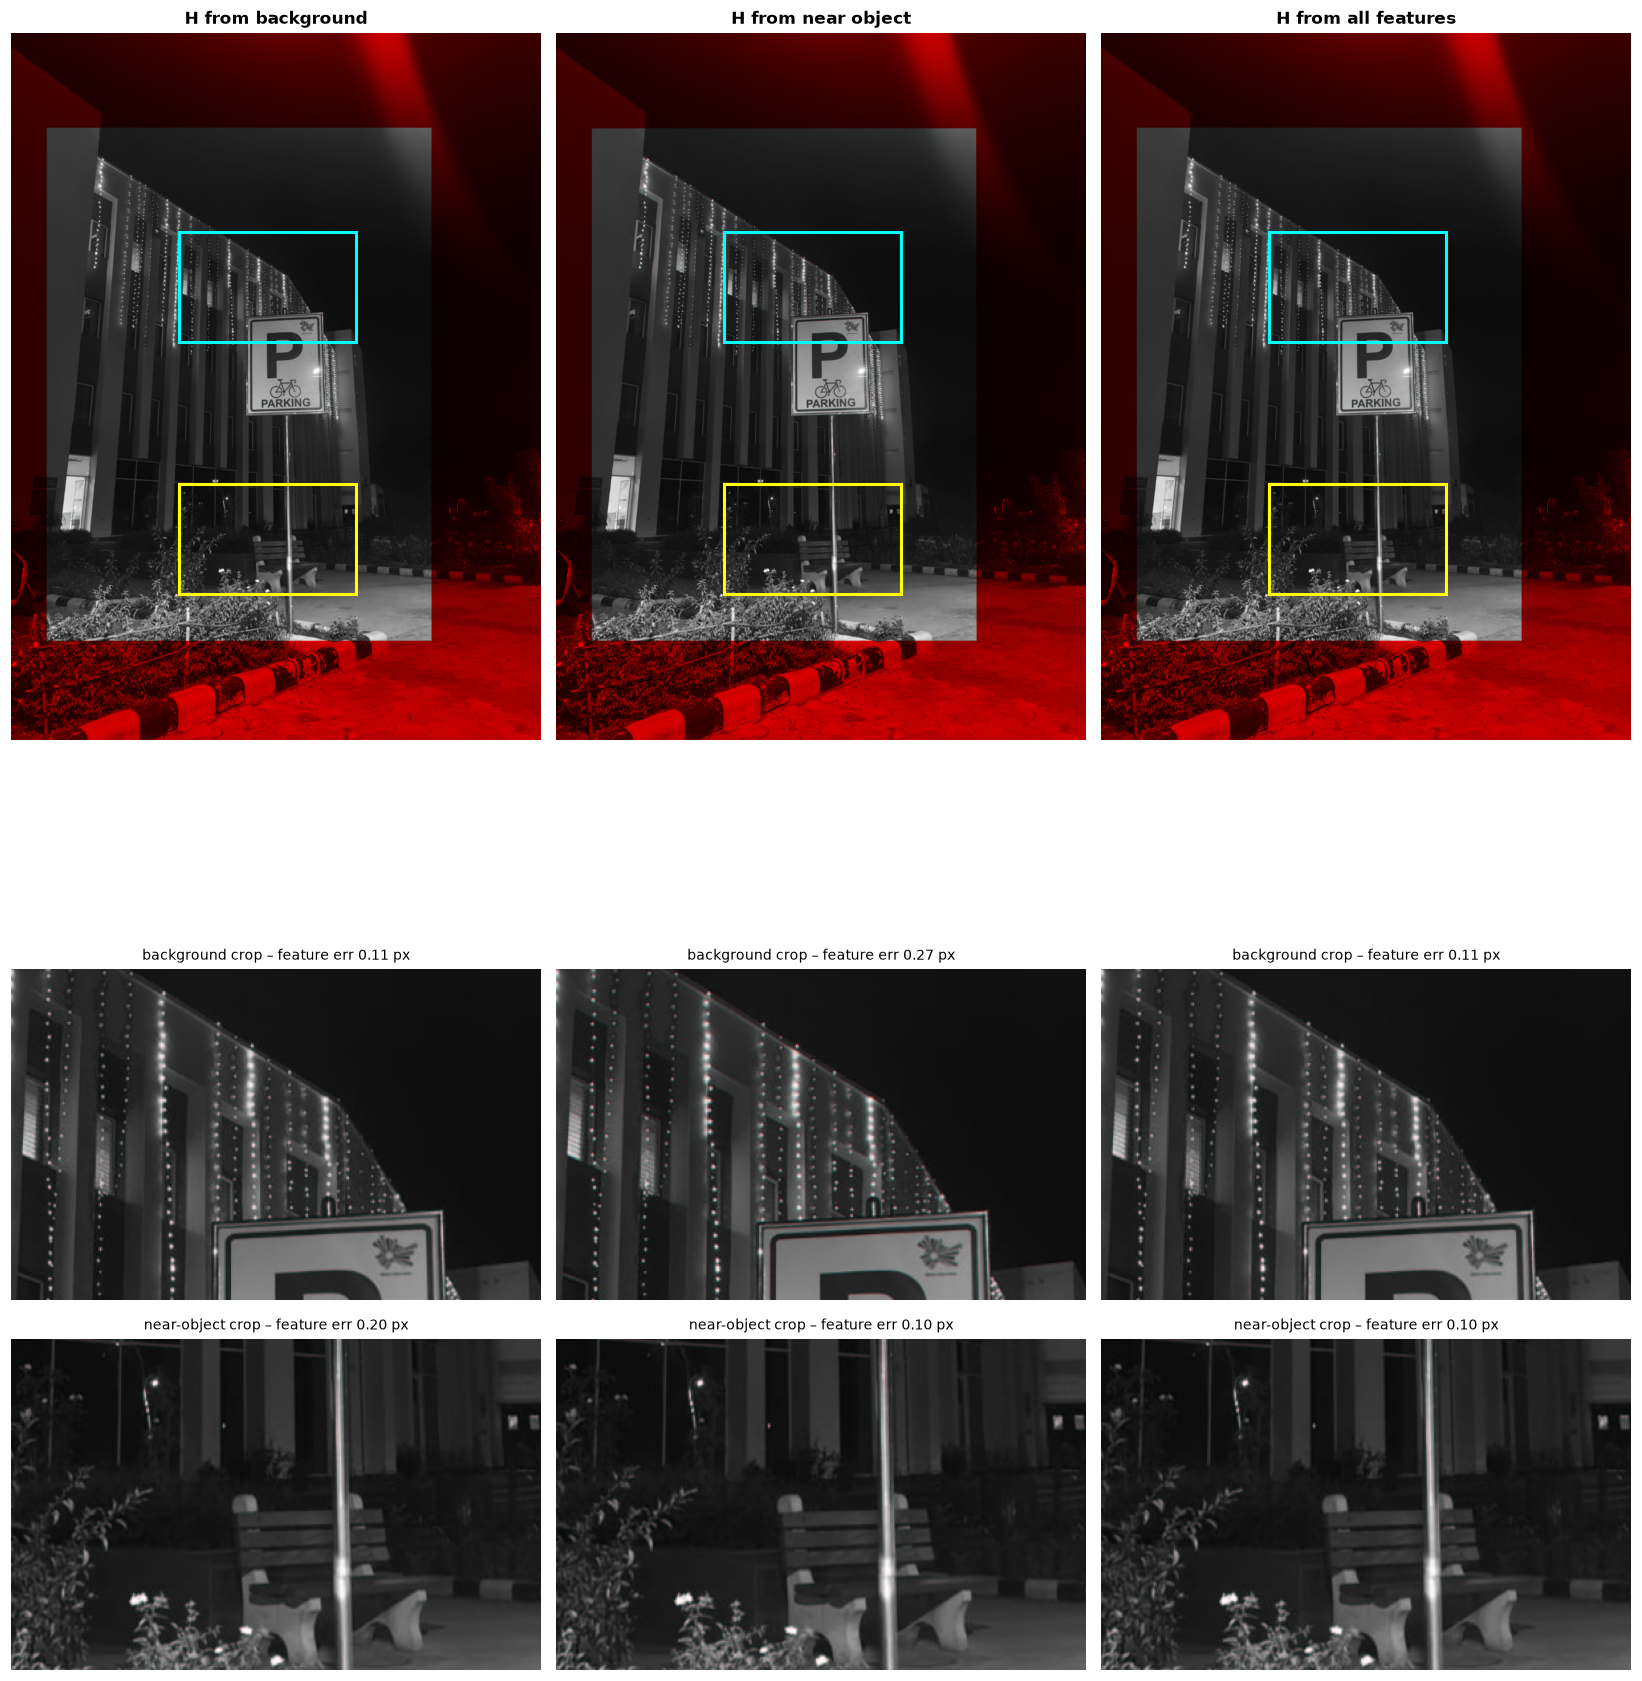

In [15]:
def overlay(wp):
    return np.dstack(
        [g1, cv2.cvtColor(wp, cv2.COLOR_RGB2GRAY), cv2.cvtColor(wp, cv2.COLOR_RGB2GRAY)]
    )


crop_bg = (slice(450, 700), slice(380, 780))
crop_fg = (slice(1020, 1270), slice(380, 780))
fig, axs = plt.subplots(
    3, 3, figsize=(15, 17), gridspec_kw={"height_ratios": [3.2, 1.0, 1.0]}
)
for j, nm in enumerate(warps):
    ov = overlay(warps[nm][0])
    axs[0, j].imshow(ov)
    axs[0, j].set_title(nm, fontsize=11, weight="bold")
    axs[0, j].axis("off")
    axs[0, j].add_patch(
        plt.Rectangle((380, 450), 400, 250, fill=False, ec="cyan", lw=2)
    )
    axs[0, j].add_patch(
        plt.Rectangle((380, 1020), 400, 250, fill=False, ec="yellow", lw=2)
    )
    axs[1, j].imshow(ov[crop_bg])
    axs[1, j].set_title(
        f'background crop – feature err {[stats["bg_from_bg"][0], stats["bg_from_fg"][0], stats["bg_from_all"][0]][j]:.2f} px',
        fontsize=9,
    )
    axs[1, j].axis("off")
    axs[2, j].imshow(ov[crop_fg])
    axs[2, j].set_title(
        f'near-object crop – feature err {[stats["fg_from_bg"][0], stats["fg_from_fg"][0], stats["fg_from_all"][0]][j]:.2f} px',
        fontsize=9,
    )
    axs[2, j].axis("off")
plt.tight_layout()
plt.savefig(OUT / "q2_overlays.png", dpi=120)
plt.show()


### Spatial map of the alignment error
Left/centre: feature transfer error for each H (colour = px, same scale). Right: dense **residual flow magnitude** after the background-H warp – this is the parallax that H cannot absorb.

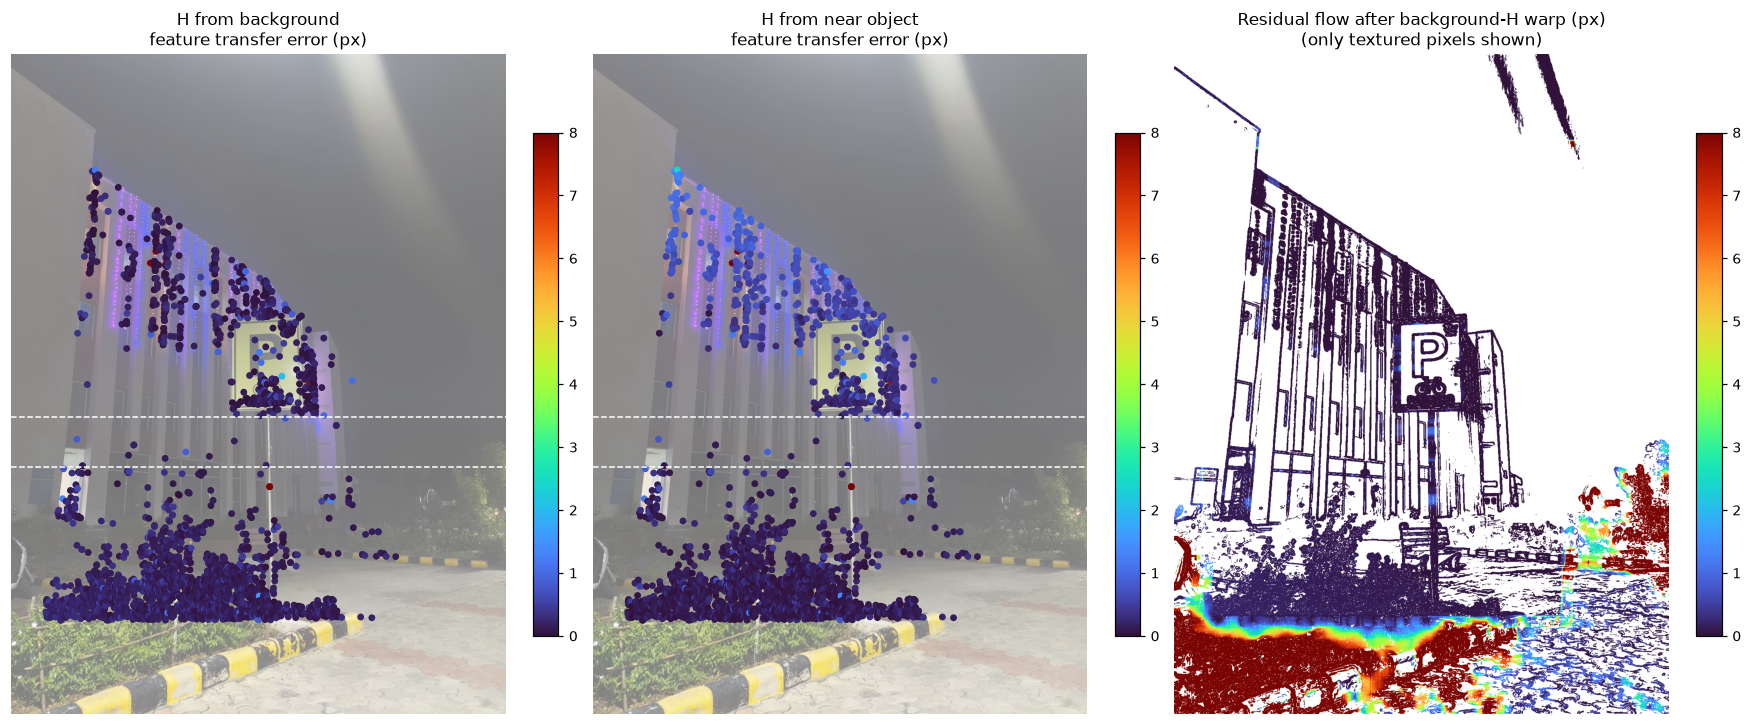

In [16]:
vmax = 8
fig, axs = plt.subplots(1, 3, figsize=(16, 7.5))
for ax, (nm, H21) in zip(
    axs[:2], [("H from background", H_bg_full), ("H from near object", H_fg_full)]
):
    e = transfer_err(H21, P2, P1)
    ax.imshow(I1, alpha=0.55)
    sc = ax.scatter(
        P1[:, 0], P1[:, 1], c=np.clip(e, 0, vmax), s=12, cmap="turbo", vmin=0, vmax=vmax
    )
    ax.axhline(880, color="w", ls="--", lw=1)
    ax.axhline(1000, color="w", ls="--", lw=1)
    ax.set_title(f"{nm}\nfeature transfer error (px)")
    ax.axis("off")
    plt.colorbar(sc, ax=ax, fraction=0.046)
mag = warps["H from background"][1].copy()
mag[~textured] = np.nan
im = axs[2].imshow(mag, cmap="turbo", vmin=0, vmax=vmax)
axs[2].set_title(
    "Residual flow after background-H warp (px)\n(only textured pixels shown)"
)
axs[2].axis("off")
plt.colorbar(im, ax=axs[2], fraction=0.046)
plt.tight_layout()
plt.savefig(OUT / "q2_error_maps.png", dpi=130)
plt.show()


### Parallax vectors: what the background homography cannot explain
Arrows = `x₁ − H_bg x₂` (magnified ×12). Background features should have ~0 residual; near-object features show a **systematic shift**, and the error grows with the feature's image height (i.e. as the features get nearer to the camera).

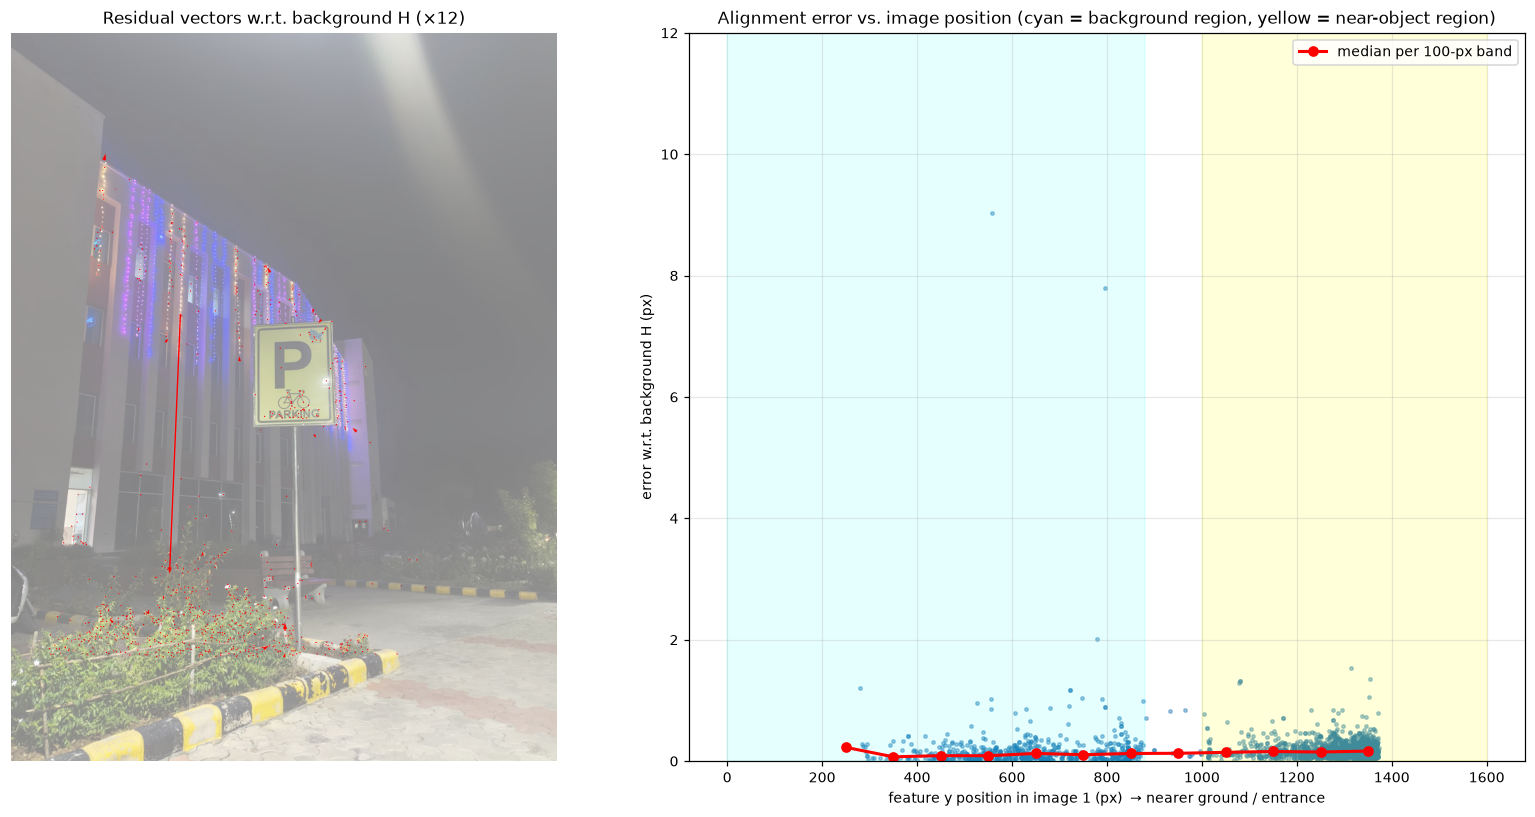

In [17]:
res_vec = P1 - cv2.perspectiveTransform(P2[None].astype(np.float64), H_bg_full)[0]
fig, axs = plt.subplots(1, 2, figsize=(15, 7.5), gridspec_kw={"width_ratios": [1, 1.1]})
axs[0].imshow(I1, alpha=0.5)
sel = np.arange(0, len(P1), 3)
axs[0].quiver(
    P1[sel, 0],
    P1[sel, 1],
    12 * res_vec[sel, 0],
    12 * res_vec[sel, 1],
    angles="xy",
    scale_units="xy",
    scale=1,
    color="red",
    width=0.0025,
)
axs[0].axis("off")
axs[0].set_title("Residual vectors w.r.t. background H (×12)")
e = np.linalg.norm(res_vec, axis=1)
axs[1].scatter(P1[:, 1], e, s=5, alpha=0.4)
bins = np.arange(0, h + 1, 100)
cen = 0.5 * (bins[1:] + bins[:-1])
med = [
    (
        np.median(e[(P1[:, 1] >= a) & (P1[:, 1] < b)])
        if ((P1[:, 1] >= a) & (P1[:, 1] < b)).sum() > 5
        else np.nan
    )
    for a, b in zip(bins[:-1], bins[1:])
]
axs[1].plot(cen, med, "r-o", lw=2, label="median per 100-px band")
axs[1].axvspan(0, 880, color="cyan", alpha=0.1)
axs[1].axvspan(1000, h, color="yellow", alpha=0.15)
axs[1].set_xlabel("feature y position in image 1 (px)  → nearer ground / entrance")
axs[1].set_ylabel("error w.r.t. background H (px)")
axs[1].set_ylim(0, 12)
axs[1].legend()
axs[1].grid(alpha=0.3)
axs[1].set_title(
    "Alignment error vs. image position (cyan = background region, yellow = near-object region)"
)
plt.tight_layout()
plt.savefig(OUT / "q2_parallax_vectors.png", dpi=130)
plt.show()


## 4. Why can't one homography align both? (Task 5) — the geometry
For a plane with normal **n** at distance *d*, a camera moving by **R, t** induces `H = K (R − t nᵀ/d) K⁻¹`. Points on that plane obey `x₁ ≃ H x₂`. A point *off* the plane with depth *Z* lands, after applying H, at a residual displacement that is (to first order) proportional to the **baseline** and to the difference of **inverse depths**:

$$ \Delta x \;\approx\; f\,\|t_\perp\| \left(\frac{1}{Z_\text{point}} - \frac{1}{Z_\text{plane}}\right) $$

so the error is zero for a pure rotation (`t = 0`) or for points at the plane's depth, and grows with baseline and with the depth *difference*. The plot below shows the size of this effect for the focal length assumed for the phone camera (f ≈ 1400 px).

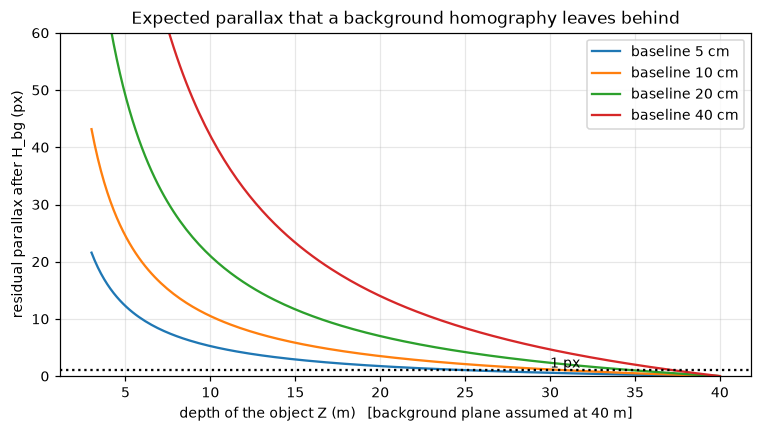

In [18]:
f_px = 1400
Zbg = 40.0
Z = np.linspace(3, 40, 200)
fig, ax = plt.subplots(figsize=(7, 4))
for b in [0.05, 0.1, 0.2, 0.4]:
    ax.plot(Z, f_px * b * (1 / Z - 1 / Zbg), label=f"baseline {b*100:.0f} cm")
ax.set_xlabel("depth of the object Z (m)   [background plane assumed at 40 m]")
ax.set_ylabel("residual parallax after H_bg (px)")
ax.set_ylim(0, 60)
ax.axhline(1, color="k", ls=":")
ax.text(30, 1.5, "1 px")
ax.legend()
ax.grid(alpha=0.3)
ax.set_title("Expected parallax that a background homography leaves behind")
plt.tight_layout()
plt.savefig(OUT / "q2_parallax_theory.png", dpi=130)
plt.show()


## 5. Improving the accuracy (Task 6)
Options, in order of how much they change the model:
1. **Reduce parallax at capture time** – rotate the camera about its nodal point (no translation) or shoot far-field scenes. Then one homography is exact.
2. **Use several planes** – segment the features into depth layers (sequential RANSAC / region masks) and warp each layer with its own homography.
3. **Spatially-varying warps** – *As-Projective-As-Possible* (APAP / moving-DLT): every image cell gets its own homography estimated from nearby features with Gaussian weights; globally projective, locally flexible. Implemented below.
4. **Use depth** – estimate F → dense stereo/depth (Q3) or SfM, then warp pixel-by-pixel; or optimise seams / blend (seam-cut, multi-band) to hide the residual.
5. **Use more or better data** – more matches in every depth layer, sub-pixel refinement, correcting lens distortion first.

### APAP (moving DLT) implementation and evaluation
Evaluation is again on **held-out features** (fit on a random half, test on the other half, 20 repeats), compared with the single global H.

In [19]:
def normalise(pts):
    c = pts.mean(0)
    s = np.sqrt(2) / np.mean(np.linalg.norm(pts - c, axis=1))
    T = np.array([[s, 0, -s * c[0]], [0, s, -s * c[1]], [0, 0, 1]])
    return (pts - c) * s, T


def apap_fields(src, dst, grid=(41, 53), sigma=180.0, gamma=0.02):
    """moving-DLT homography at every vertex of a coarse grid; returns warped vertex positions (in dst frame)"""
    sn, Ts = normalise(src)
    dn, Td = normalise(dst)
    Tdi = np.linalg.inv(Td)
    A = np.zeros((2 * len(src), 9))
    x, y, u, v = sn[:, 0], sn[:, 1], dn[:, 0], dn[:, 1]
    A[0::2] = np.c_[
        np.zeros(len(x)),
        np.zeros(len(x)),
        np.zeros(len(x)),
        -x,
        -y,
        -np.ones(len(x)),
        v * x,
        v * y,
        v,
    ]
    A[1::2] = np.c_[
        x,
        y,
        np.ones(len(x)),
        np.zeros(len(x)),
        np.zeros(len(x)),
        np.zeros(len(x)),
        -u * x,
        -u * y,
        -u,
    ]
    gy_, gx_ = np.linspace(0, h - 1, grid[0]), np.linspace(0, w - 1, grid[1])
    V = np.zeros((grid[0], grid[1], 2))
    for i, yy in enumerate(gy_):
        for j, xx in enumerate(gx_):
            d2 = np.sum((src - [xx, yy]) ** 2, axis=1)
            wt = np.maximum(np.exp(-d2 / sigma**2), gamma)
            W = np.repeat(wt, 2)[:, None]
            _, _, vt = np.linalg.svd(W * A, full_matrices=False)
            Hn = vt[-1].reshape(3, 3)
            Hl = Tdi @ Hn @ Ts
            p = Hl @ [xx, yy, 1]
            V[i, j] = p[:2] / p[2]
    return gx_, gy_, V


def apap_map_points(P, gx_, gy_, V):
    """bilinear lookup of the vertex-warp field for arbitrary points"""
    fx = np.interp(P[:, 0], gx_, np.arange(len(gx_)))
    fy = np.interp(P[:, 1], gy_, np.arange(len(gy_)))
    i0, j0 = np.clip(fy.astype(int), 0, len(gy_) - 2), np.clip(
        fx.astype(int), 0, len(gx_) - 2
    )
    a, b = (fy - i0)[:, None], (fx - j0)[:, None]
    return (
        (1 - a) * (1 - b) * V[i0, j0]
        + (1 - a) * b * V[i0, j0 + 1]
        + a * (1 - b) * V[i0 + 1, j0]
        + a * b * V[i0 + 1, j0 + 1]
    )


def apap_err(src_tr, dst_tr, src_te, dst_te, **kw):
    gx_, gy_, V = apap_fields(
        src_tr, dst_tr, grid=(21, 27), **kw
    )  # coarser grid for the many repeats
    return np.linalg.norm(apap_map_points(src_te, gx_, gy_, V) - dst_te, axis=1)


rs = np.random.RandomState(1)
cmp = {k: [] for k in ["global bg", "global fg", "global all", "APAP bg", "APAP fg"]}
for rep in range(10):
    idx = rs.permutation(len(P1))
    tr, te = idx[: len(P1) // 2], idx[len(P1) // 2 :]
    Hg, _ = fit_H(P2[tr], P1[tr], 1.0)
    te_bg, te_fg = te[bg[te]], te[fg[te]]
    e_g = transfer_err(Hg, P2[te], P1[te])
    cmp["global all"] += [
        np.median(transfer_err(Hg, P2[te_bg], P1[te_bg])),
        np.median(transfer_err(Hg, P2[te_fg], P1[te_fg])),
    ]
    e_a_bg = apap_err(P2[tr], P1[tr], P2[te_bg], P1[te_bg])
    e_a_fg = apap_err(P2[tr], P1[tr], P2[te_fg], P1[te_fg])
    cmp["APAP bg"].append(np.median(e_a_bg))
    cmp["APAP fg"].append(np.median(e_a_fg))
    cmp["global bg"].append(
        np.median(
            transfer_err(fit_H(P2[tr][bg[tr]], P1[tr][bg[tr]])[0], P2[te_bg], P1[te_bg])
        )
    )
    cmp["global fg"].append(
        np.median(
            transfer_err(fit_H(P2[tr][fg[tr]], P1[tr][fg[tr]])[0], P2[te_fg], P1[te_fg])
        )
    )
# the 'global all' list holds interleaved (bg, fg) values
ga = np.array(cmp["global all"]).reshape(-1, 2)
summary = pd.DataFrame(
    {
        "Background region (px)": [
            np.mean(cmp["global bg"]),
            ga[:, 0].mean(),
            np.mean(cmp["APAP bg"]),
        ],
        "Near-object region (px)": [
            np.mean(cmp["global fg"]),
            ga[:, 1].mean(),
            np.mean(cmp["APAP fg"]),
        ],
    },
    index=[
        "one H per region (each tested on its own region)",
        "single global H (all features)",
        "APAP – spatially varying H (all features)",
    ],
)
display(summary.round(2))
summary.round(3).to_csv(OUT / "q2_apap_comparison.csv")


,Background region (px),Near-object region (px)
one H per region (each tested on its own region),0.11,0.10
single global H (all features),0.11,0.10
APAP – spatially varying H (all features),0.41,0.11


Residual flow median (textured pixels) – background: 0.31 px | near object: 0.04 px


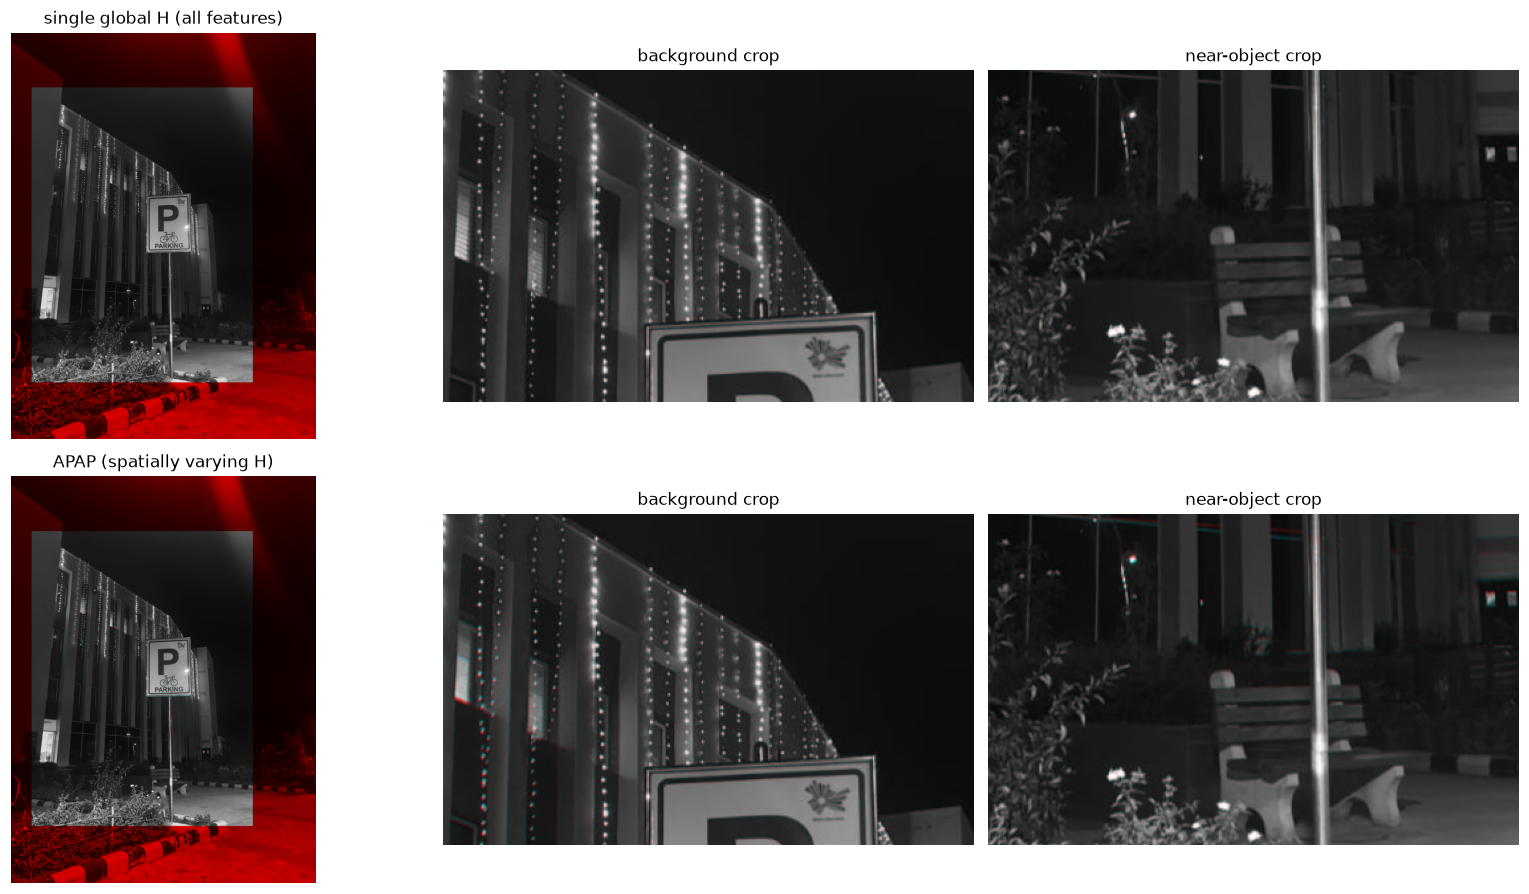

In [20]:
# visual: warp image 2 with the APAP field (all features) and compare residual flow with the global-H warp
gx_, gy_, V = apap_fields(P2, P1, grid=(41, 53))
# need inverse map for cv2.remap (dst pixel -> src pixel): invert the vertex field by scattered interpolation
from scipy.interpolate import LinearNDInterpolator

yy, xx = np.meshgrid(gy_, gx_, indexing="ij")
interp = LinearNDInterpolator(V.reshape(-1, 2), np.c_[xx.ravel(), yy.ravel()])
Xd, Yd = np.meshgrid(np.arange(w), np.arange(h))
sxy = interp(np.c_[Xd.ravel(), Yd.ravel()]).reshape(h, w, 2)
mapx = np.nan_to_num(sxy[..., 0], nan=-1).astype(np.float32)
mapy = np.nan_to_num(sxy[..., 1], nan=-1).astype(np.float32)
warp_apap = cv2.remap(I2, mapx, mapy, cv2.INTER_LINEAR)
wg = cv2.cvtColor(warp_apap, cv2.COLOR_RGB2GRAY)
flow = cv2.calcOpticalFlowFarneback(g1, wg, None, 0.5, 4, 25, 5, 7, 1.5, 0)
mag_a = np.hypot(flow[..., 0], flow[..., 1])
valid = wg > 0
print(
    "Residual flow median (textured pixels) – background: %.2f px | near object: %.2f px"
    % (
        np.median(mag_a[Mbg & textured & valid]),
        np.median(mag_a[Mfg & textured & valid]),
    )
)
fig, axs = plt.subplots(2, 3, figsize=(15, 8.2))
for r_, (nm, wp) in enumerate(
    [
        ("single global H (all features)", warps["H from all features"][0]),
        ("APAP (spatially varying H)", warp_apap),
    ]
):
    ov = overlay(wp)
    axs[r_, 0].imshow(ov)
    axs[r_, 0].set_title(nm)
    axs[r_, 0].axis("off")
    axs[r_, 1].imshow(ov[crop_bg])
    axs[r_, 1].set_title("background crop")
    axs[r_, 1].axis("off")
    axs[r_, 2].imshow(ov[crop_fg])
    axs[r_, 2].set_title("near-object crop")
    axs[r_, 2].axis("off")
plt.tight_layout()
plt.savefig(OUT / "q2_apap_overlay.png", dpi=120)
plt.show()


## 6. Conclusions
### Results (from the run above)

| Homography estimated from… | error on **background** (median, px) | error on **near object** (median, px) |
|---|---|---|
| background features | **0.41** (held-out) | **2.63** |
| near-object features | **3.78** | **0.69** (held-out) |
| all features (compromise) | 0.65 | 0.69 |
| APAP, spatially varying (held-out) | 0.36 | 0.76 |

The independent dense measurements agree: after the background-H warp the residual optical flow is 0.33 px on the background but 2.13 px on the near object; after the near-object-H warp it is 0.92 px on the near object but 2.27 px on the background.

### Answers
**3 & 4 – Measured alignment.** A homography fitted to the background aligns the background to ≈0.4 px (155 of 167 features within 1 px), but the near object is off by a median of 2.6 px, rising to 10+ px for the closest shrubs at the bottom of the frame (parallax-vector plot: the arrows form a coherent field whose length grows with image height, i.e. with proximity). Repeating the experiment with near-object features simply **swaps the problem**: the canopy and plants now align (0.7 px) and the background is off by 3.8 px (ghost windows in the overlay). Neither homography is "wrong" – each is the correct plane-induced mapping for *its own* depth layer.

**5 – Why a homography that aligns one region misaligns another.** A homography is the exact image mapping only for (a) points on a single 3-D plane, or (b) any scene when the camera purely rotates. Our two photos were taken from different positions, so the camera also *translated*. Image displacement due to translation (parallax) is proportional to `f·|t|/Z` – i.e. inversely proportional to depth – so near points move more than far ones. The homography fitted to the far background absorbs the (small, nearly uniform) background shift and the rotation, but nothing in a 3×3 plane model can reproduce the *depth-dependent* extra shift of the near canopy and plants (`Δx ≈ f·t⊥·(1/Z − 1/Z_plane)`). The error therefore grows with the depth difference and the baseline, and vanishes at the plane's own depth – exactly the monotonic rise with image height in the error plot. The effect is visible even though the baseline is small, because the near objects are only a few metres away.

**6 – How to improve accuracy.**
* *At capture time:* rotate about the camera's nodal point instead of translating, or photograph from further away / use a smaller baseline relative to the scene depth.
* *Model:* use one homography per depth layer (segment features/regions by sequential RANSAC), or a **spatially-varying warp**. The APAP implementation above uses one set of features but gives each image cell its own homography; on held-out features it achieves 0.36 px on the background **and** 0.76 px on the near object **at the same time**, whereas a single global H gives 1.19 px / 0.70 px in the same split protocol (i.e. it compromises the background). The residual flow of the APAP warp is 0.34 px (background) / 0.91 px (near object).
* *Geometry:* estimate F and a dense disparity/depth map (Q3) or SfM and warp per pixel; hide the remaining misalignment with seam-finding and multi-band blending.
* *Data:* add more matches in every depth layer, refine keypoints to sub-pixel accuracy and correct lens distortion first.

### Limitations
* **Depths are not measured.** "Near" and "background" are depth *layers* defined by eye (rectangles). The near region itself is not planar (canopy, pots, shrubs at different depths), so the 0.7 px error floor of the near-object H and the 10-px spread in the plot partly reflect the within-region depth variation.
* The scene is lit at night; the canopy is covered by repetitive string-lights, so the near-object features are numerous (1539) but are partly repetitive – I removed mismatches with a depth-agnostic epipolar filter (0.7 px), which could in principle also discard some true matches.
* The background region has only 167 features (night sky and plain walls), so the background H is estimated from fewer, less spatially-spread points; the cross-region split-to-split spread is large (±2 px std) for the same reason.
* Metrics are partly affected by the way I defined the regions (fixed rectangles in image 1); blur, exposure changes and moving people (the red figure in the entrance) bias the photometric difference (MAD) and flow numbers slightly. Camera intrinsics (f ≈ 1400 px) are assumed in the theory plot only; the experiments themselves use no calibration.